In [1]:
import yfinance as yf
import datetime

startdt="2025-01-01"
enddt = datetime.date.today().strftime("%Y-%m-%d")

# Download Reliance stock data
reliance = yf.download("CUMMINSIND.NS", start=startdt, end=enddt)

print(reliance.tail())


/tmp/ipykernel_159330/3905056775.py:8: FutureWarning: YF.download() has changed argument auto_adjust default to True
  reliance = yf.download("CUMMINSIND.NS", start=startdt, end=enddt)
[*********************100%***********************]  1 of 1 completed

Price              Close          High           Low          Open  \
Ticker     CUMMINSIND.NS CUMMINSIND.NS CUMMINSIND.NS CUMMINSIND.NS   
Date                                                                 
2026-04-10   5138.700195   5154.899902   4908.600098        4961.0   
2026-04-13   4991.399902   5116.799805   4982.000000        5030.0   
2026-04-15   5003.399902   5120.000000   4986.600098        5090.0   
2026-04-16   5038.200195   5055.000000   4951.000000        5024.0   
2026-04-17   5140.899902   5179.899902   5011.200195        5043.0   

Price             Volume  
Ticker     CUMMINSIND.NS  
Date                      
2026-04-10       1308552  
2026-04-13        869786  
2026-04-15        806914  
2026-04-16        666008  
2026-04-17        529710  


Stock Cumulative Returns

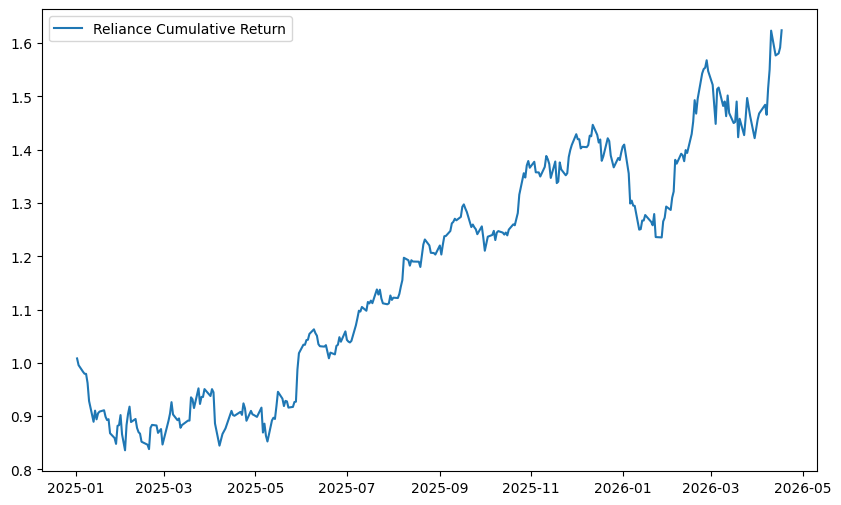

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Daily returns
reliance['Daily Return'] = reliance['Close'].pct_change()

# Cumulative returns
reliance['Cumulative Return'] = (1 + reliance['Daily Return']).cumprod()

# Plot
plt.figure(figsize=(10,6))
plt.plot(reliance['Cumulative Return'], label="Reliance Cumulative Return")
plt.legend()
plt.show()


Compare Trends of multiple stocks

/tmp/ipykernel_159330/1959257618.py:6: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(stocks, start=startdt, end=enddt)['Close']
[*********************100%***********************]  3 of 3 completed


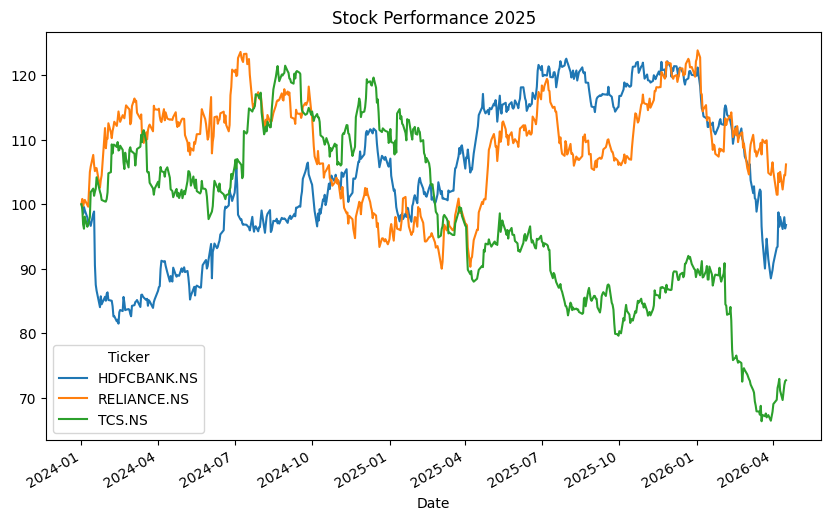

In [3]:
stocks = ["RELIANCE.NS", "TCS.NS", "HDFCBANK.NS"]

startdt="2024-01-01"
enddt = datetime.date.today().strftime("%Y-%m-%d")

data = yf.download(stocks, start=startdt, end=enddt)['Close']

# Normalize (start at 100)
normalized = data / data.iloc[0] * 100

normalized.plot(figsize=(10,6))
plt.title("Stock Performance 2025")
plt.show()


Moving average of particular stock

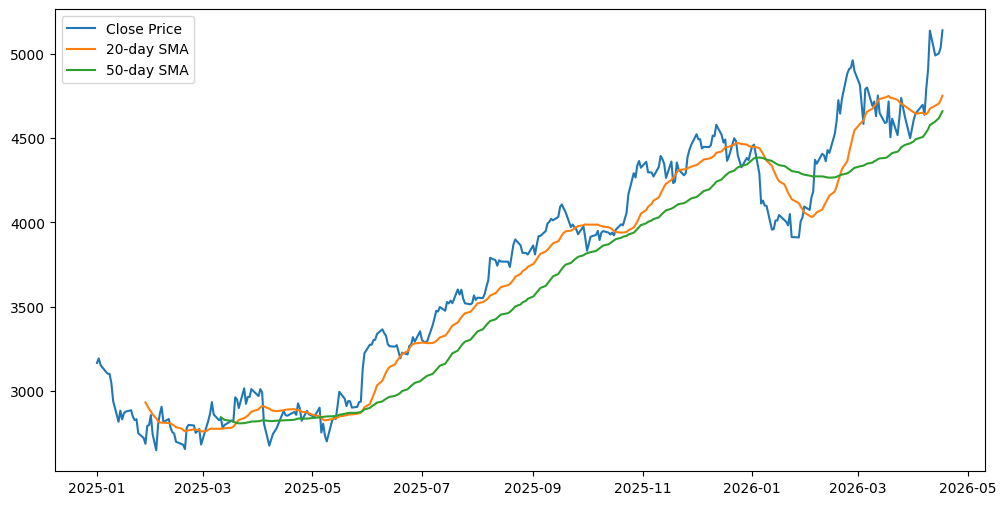

In [4]:
reliance['SMA_20'] = reliance['Close'].rolling(20).mean()
reliance['SMA_50'] = reliance['Close'].rolling(50).mean()

plt.figure(figsize=(12,6))
plt.plot(reliance['Close'], label="Close Price")
plt.plot(reliance['SMA_20'], label="20-day SMA")
plt.plot(reliance['SMA_50'], label="50-day SMA")
plt.legend()
plt.show()


Performance of stock vs Nifty

In [5]:

nifty = yf.download("^NSEI", start=startdt, end=enddt)['Close']

# Normalize both
comparison = pd.DataFrame({
    "Reliance": reliance['Close']/reliance['Close'].iloc[0]*100,
    "Nifty50": nifty/nifty.iloc[0]*100
})

comparison.plot(figsize=(10,6))
plt.title("Reliance vs Nifty50")
plt.show()


/tmp/ipykernel_159330/2793035632.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  nifty = yf.download("^NSEI", start=startdt, end=enddt)['Close']
[*********************100%***********************]  1 of 1 completed


ValueError: If using all scalar values, you must pass an index